In [1]:
# =====================================
# CNN1D ONLY TIMESERIES EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_cnn_timeseries_classifier import RunTimeSeriesCNN
from src.run.preprocess.config import _project_path

[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7325 | val_loss=0.6269 | train_accuracy=0.4000 | val_accuracy=0.8000
Fold 01 | Epoch 02 | train_loss=0.6008 | val_loss=0.5329 | train_accuracy=0.7167 | val_accuracy=0.8000
Fold 01 | Epoch 03 | train_loss=0.5711 | val_loss=0.4847 | train_accuracy=0.7333 | val_accuracy=0.8000
Fold 01 | Epoch 04 | train_loss=0.5847 | val_loss=0.4853 | train_accuracy=0.7333 | val_accuracy=0.8000
Fold 01 | Epoch 05 | train_loss=0.5746 | val_loss=0.5390 | train_accuracy=0.7167 | val_accuracy=0.6000
Fold 01 | Epoch 06 | train_loss=0.5819 | val_loss=0.5146 | train_accuracy=0.7500 | val_accuracy=0.6667
Fold 01 | Epoch 07 | train_loss=0.5577 | val_loss=0.4939 | train_accuracy=0.7167 | val_accuracy=0.9333
Fold 01 | Epoch 08 | train_loss=0.5386 | val_loss=0.4839 | train_accuracy=0.7333 | val_accuracy=0.9333
Fold 01 | Epoch 09 | train_loss=0.5246 | val_loss=0.5120 | train_accuracy=0.7667 | val_accuracy=0.6667
Fold 01 

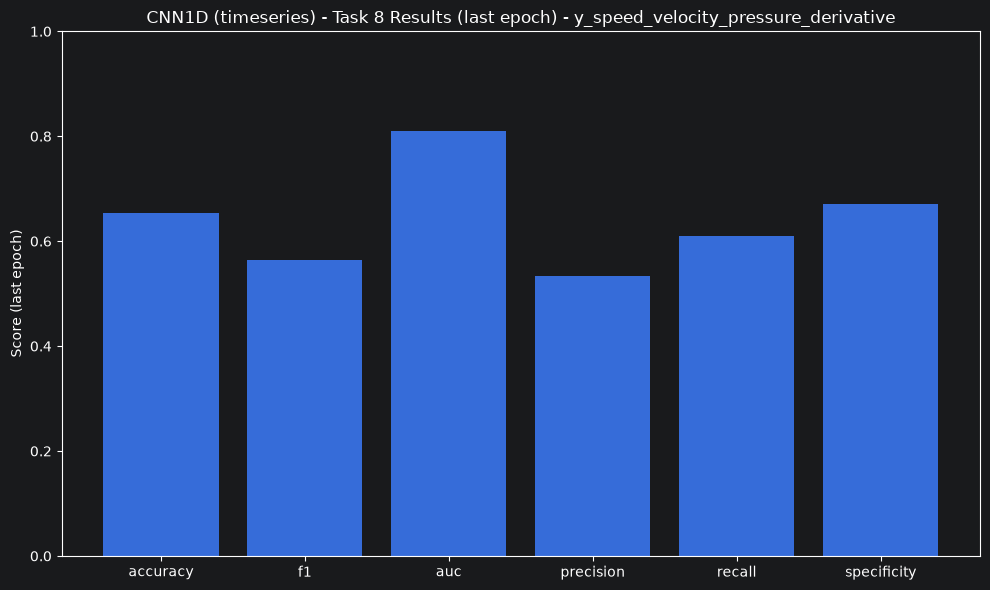

In [2]:
# =====================================
# RUN EXPERIMENT
# task 8 -> y_speed_velocity_pressure_derivative
# =====================================

runner = RunTimeSeriesCNN(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[8],
    feature_names=("y",),
    engineered_features=("speed", "velocity", "pressure_derivative",),
    batch_size=16,
    epochs=50,
    learning_rate=1e-3,
    regularization=1e-3,
    n_splits=5,
    normalize=True,
    seed=42,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    output_dir=_project_path("experiments/ant/cnn1D/cnn(timeseries)/task_8/y_speed_velocity_pressure_derivative"),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": float("inf"),
        "min_delta": 0.0,
        "results_writer": "csv",
        "save_metrics": True,
    },
)

summary = runner.run()

# =====================================
# RESULTS (last epoch)
# =====================================

averages = summary["averages"]

print("\n=== FINAL RESULTS (last epoch) ===")

print(f"Accuracy:    {averages['last_val_accuracy']:.4f}")
print(f"F1 Score:    {averages['last_val_f1']:.4f}")
print(f"AUC:         {averages['last_val_auc']:.4f}")
print(f"Precision:   {averages['last_val_precision']:.4f}")
print(f"Recall:      {averages['last_val_recall']:.4f}")
print(f"Specificity: {averages['last_val_specificity']:.4f}")

# =====================================
# BUILD DATAFRAME
# =====================================

df = pd.DataFrame([{
    "accuracy": averages["last_val_accuracy"],
    "f1": averages["last_val_f1"],
    "auc": averages["last_val_auc"],
    "precision": averages["last_val_precision"],
    "recall": averages["last_val_recall"],
    "specificity": averages["last_val_specificity"],
}])

# =====================================
# PLOT
# =====================================

metrics = [
    "accuracy",
    "f1",
    "auc",
    "precision",
    "recall",
    "specificity",
]

values = [
    averages[f"last_val_{m}"]
    for m in metrics
]

plt.figure(figsize=(10, 6))

plt.bar(
    metrics,
    values,
)

plt.ylim(0, 1)

plt.ylabel("Score (last epoch)")

plt.title(
    "CNN1D (timeseries) - Task 8 Results (last epoch) - y_speed_velocity_pressure_derivative"
)

plt.tight_layout()

plt.show()